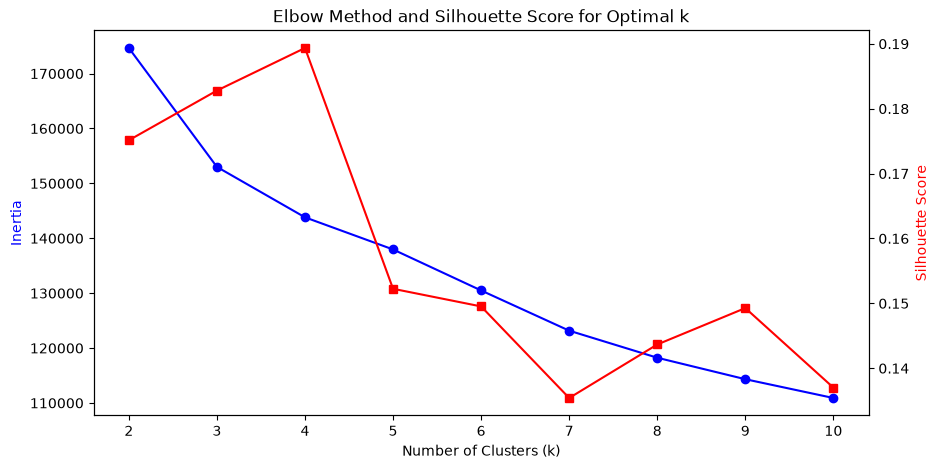

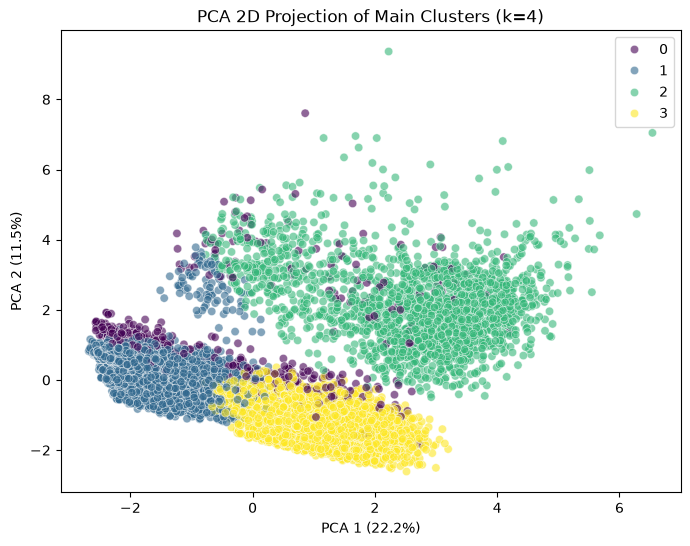

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 1. 데이터 로드 및 전처리
ml_data = pd.read_csv('KNHANES_2022_2024_ML_CLUSTER_COMPLETECASE.csv')
features = [col for col in ml_data.columns if col.startswith('ML_')]
X = ml_data[features].copy()

X_scaled = StandardScaler().fit_transform(X)

# 2. 최적 군집 수 탐색 (k=2~10)
inertia = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

# 3. 엘보우 및 실루엣 지표 시각화
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(k_range, inertia, marker='o', color='b', label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color='b')

ax2 = ax1.twinx()
ax2.plot(k_range, silhouette_scores, marker='s', color='r', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='r')
plt.title('Elbow Method and Silhouette Score for Optimal k')
plt.show()

# 4. PCA 차원 축소를 통한 2차원 군집 산점도 (k=4 기준)
kmeans_main = KMeans(n_clusters=4, random_state=42, n_init=10)
main_labels = kmeans_main.fit_predict(X_scaled)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=main_labels, palette='viridis', alpha=0.6)
plt.title('PCA 2D Projection of Main Clusters (k=4)')
plt.xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
plt.ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.show()

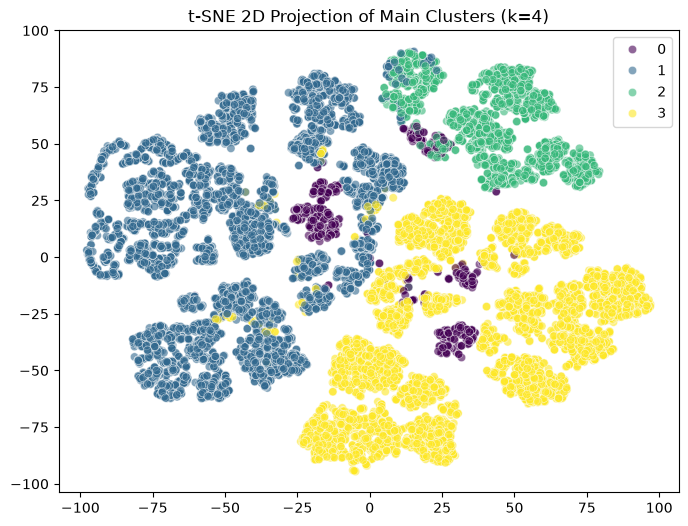

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

# 데이터 로드 및 K-Means 군집 재계산
ml_data = pd.read_csv('KNHANES_2022_2024_ML_CLUSTER_COMPLETECASE.csv')
features = [col for col in ml_data.columns if col.startswith('ML_')]
X_scaled = StandardScaler().fit_transform(ml_data[features])

kmeans_main = KMeans(n_clusters=4, random_state=42, n_init=10)
main_labels = kmeans_main.fit_predict(X_scaled)

# t-SNE 적용
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled)

# 시각화
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=main_labels, palette='viridis', alpha=0.6)
plt.title('t-SNE 2D Projection of Main Clusters (k=4)')
plt.show()

c:\Users\최지연\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\최지연\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


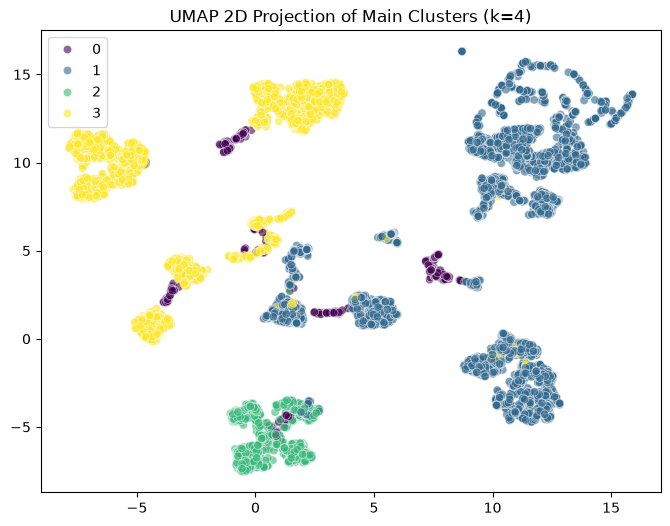

In [4]:
import umap # pip install umap-learn 

# UMAP 적용
reducer = umap.UMAP(n_components=2, random_state=42)
X_umap = reducer.fit_transform(X_scaled)

# 시각화
plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=main_labels, palette='viridis', alpha=0.6)
plt.title('UMAP 2D Projection of Main Clusters (k=4)')
plt.show()

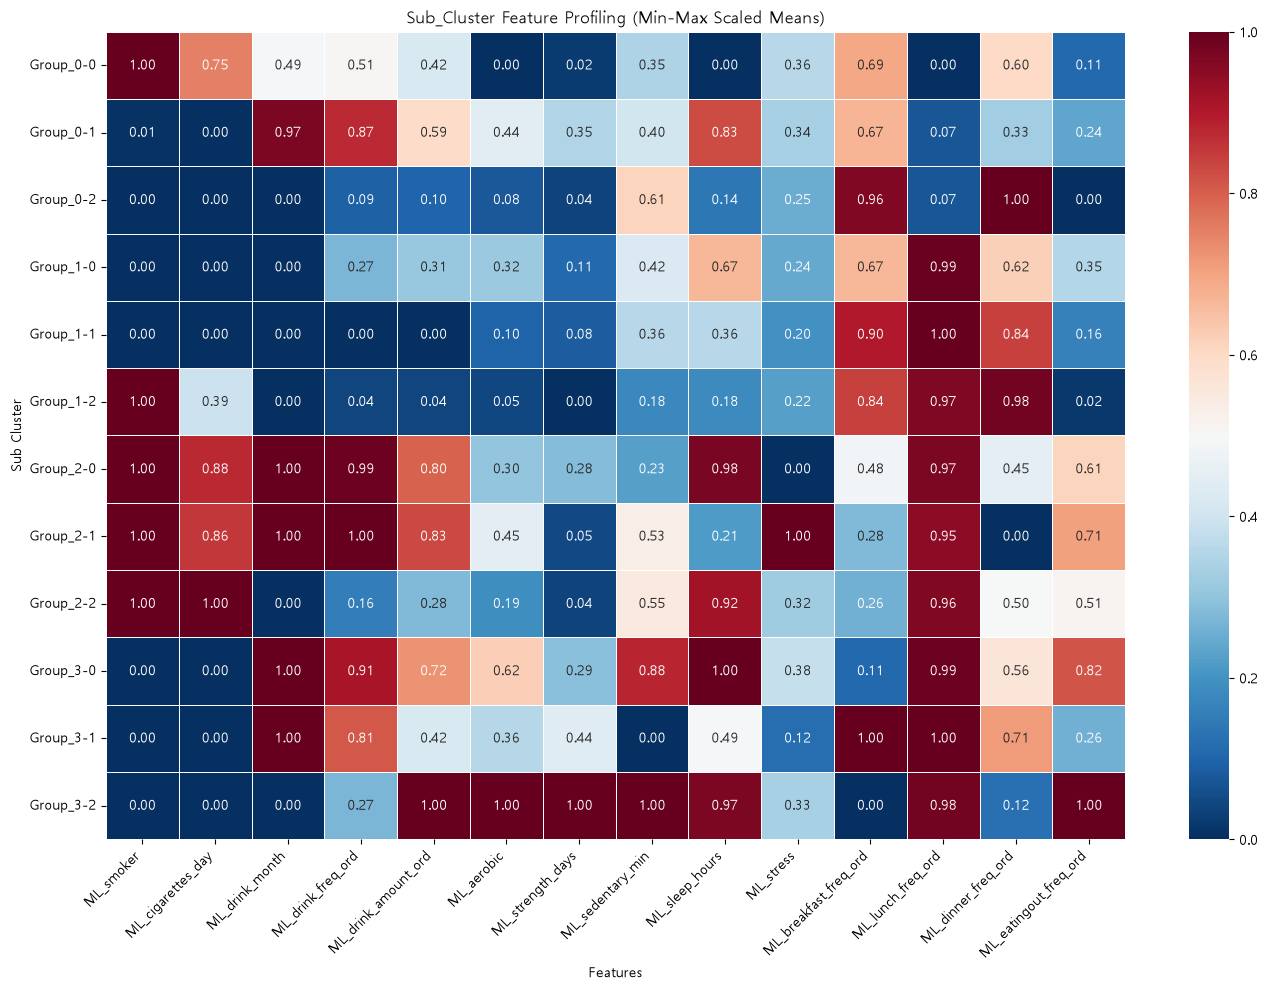

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# 1. 'Sub_Cluster' 컬럼이 포함된 최종 결과 파일 로드
ml_data = pd.read_csv('KMeans_All_Subclustered2.csv')
features = [col for col in ml_data.columns if col.startswith('ML_')]

# 2. 세부 군집(Sub_Cluster)별 평균값 집계
profile_mean = ml_data.groupby('Sub_Cluster')[features].mean()

# 3. 히트맵 색상 대비를 명확히 하기 위한 0~1 정규화 (Min-Max Scaling)
scaler = MinMaxScaler()
profile_scaled = pd.DataFrame(
    scaler.fit_transform(profile_mean), 
    index=profile_mean.index, 
    columns=profile_mean.columns
)

# 4. 히트맵 시각화 (숫자 표시 추가)
plt.figure(figsize=(14, 10)) # 숫자가 들어가므로 크기를 약간 키웠습니다.
plt.rcParams['font.family'] = 'Malgun Gothic' 
plt.rcParams['axes.unicode_minus'] = False

# annot=True 와 fmt='.2f' 추가
sns.heatmap(profile_scaled, annot=True, fmt='.2f', cmap='RdBu_r', center=0.5, linewidths=.5)

plt.title('Sub_Cluster Feature Profiling (Min-Max Scaled Means)')
plt.ylabel('Sub Cluster')
plt.xlabel('Features')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()